# 05 — Geographic Feature Engineering Review

**Objective:** Determine whether richer geographical features improve 2014–15 subscription AUROC beyond our original 39-feature CatBoost baseline.

From the repository root, first run:

```bash
python -m src.geography_experiments
```

Optionally repeat with multiple random seeds (longer runtime):

```bash
python -m src.geography_experiments --seeds 42 123 2026
```

The five experiments use identical CatBoost settings and account-level CV splits; they differ only in new geography features. All output, including the expanded **master datasets**, is under `data/processed/geography/`. The original `data/processed/` baseline and submission remain untouched.

## 1. Load geographic experiment artifacts
The `baseline` variant should match the previous master feature table: 6,941 labeled accounts and 39 predictive features.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd()
if not (ROOT / 'src' / 'geography_experiments.py').exists():
    ROOT = ROOT.parent
RESULTS = ROOT / 'data' / 'processed' / 'geography'
assert (RESULTS / 'experiment_summary.csv').exists(), (
    'Run python -m src.geography_experiments from the repository root first.'
)

summary = pd.read_csv(RESULTS / 'experiment_summary.csv')
runs = pd.read_csv(RESULTS / 'experiment_runs.csv')
folds = pd.read_csv(RESULTS / 'experiment_folds.csv')
oof = pd.read_csv(RESULTS / 'experiment_oof_predictions.csv', dtype={'account.id': 'string'})
manifest = pd.read_csv(RESULTS / 'feature_manifest.csv')
importance_path = RESULTS / 'catboost_feature_importance.csv'
importance = pd.read_csv(importance_path) if importance_path.exists() else None
with (RESULTS / 'experiment_config.json').open(encoding='utf-8') as f:
    config = json.load(f)

print('Model:', config['model'])
print('Folds:', config['folds'], '| Seeds:', config['seeds'])
print('Feature variants:', config['modes'])
print('Labeled accounts:', len(oof))
print('Venue reference ZIPs:', config['venue_reference_zip_centroids'])

Model: catboost
Folds: 5 | Seeds: [42]
Feature variants: ['baseline', 'demographics', 'distance', 'density', 'all']
Labeled accounts: 6941
Venue reference ZIPs: {'san_francisco': '94102', 'berkeley': '94704', 'palo_alto': '94301', 'stanford': '94305'}


## 2. Inspect the expanded master datasets
These tables let us **see what the feature pipeline actually produced**, not just its model score. Each variant contains one record per account; the ZIP-derived fields are computed without using target labels.

In [2]:
variant = 'all' if 'all' in config['modes'] else config['modes'][-1]
vdir = RESULTS / 'variants' / variant
train = pd.read_csv(vdir / 'train_features.csv',
                    dtype={'account.id': 'string', 'billing_zip': 'string'})
test = pd.read_csv(vdir / 'test_features.csv',
                   dtype={'account.id': 'string', 'billing_zip': 'string'})
geo_cols = [col for col in train if col.startswith('geo_')]
print(f'{variant} train: {train.shape}; test: {test.shape}')
print(f'New geographic features ({len(geo_cols)}):', geo_cols)
display(train[['account.id', 'label', 'billing_zip', 'zip_lat', 'zip_long',
               *geo_cols]].head(12))

missing = train[geo_cols].isna().mean().mul(100).sort_values(ascending=False)
display(missing.rename('Missing (%)').to_frame().round(2))
print('Train/test columns aligned:', [c for c in train if c != 'label'] == test.columns.tolist())

all train: (6941, 57); test: (2975, 56)
New geographic features (16): ['geo_zip_tax_returns', 'geo_zip_est_population', 'geo_zip_total_wages', 'geo_zip_wages_per_return', 'geo_zip_people_per_return', 'geo_distance_san_francisco_km', 'geo_distance_berkeley_km', 'geo_distance_palo_alto_km', 'geo_distance_stanford_km', 'geo_distance_nearest_km', 'geo_nearest_venue_area', 'geo_distance_peninsula_km', 'geo_zip_other_patron_count', 'geo_zip_other_active_subscribers', 'geo_zip_other_active_share_smoothed', 'geo_zip_log_other_patrons']


,account.id,label,billing_zip,zip_lat,zip_long,geo_zip_tax_returns,geo_zip_est_population,geo_zip_total_wages,geo_zip_wages_per_return,geo_zip_people_per_return,...,geo_distance_berkeley_km,geo_distance_palo_alto_km,geo_distance_stanford_km,geo_distance_nearest_km,geo_nearest_venue_area,geo_distance_peninsula_km,geo_zip_other_patron_count,geo_zip_other_active_subscribers,geo_zip_other_active_share_smoothed,geo_zip_log_other_patrons
0,001i000000NuRo3,0,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,001i000000NuRxd,0,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,001i000000NuQGN,0,94597,37.91,-122.07,10755.0,16977.0,6.592431e+08,61296.428731,1.578522,...,16.746656,52.733821,56.290085,16.746656,berkeley,52.733821,61.0,6.0,0.086300,4.127134
3,001i000000NuPfL,0,94005,37.68,-122.41,2641.0,4345.0,1.997331e+08,75627.836047,1.645210,...,24.461950,35.176944,36.729753,10.007557,san_francisco,35.176944,10.0,0.0,0.033009,2.397895
4,001i000000NuQkP,0,94610,37.81,-122.24,16601.0,24162.0,1.004840e+09,60528.908861,1.455454,...,5.628685,41.898727,44.903401,5.628685,berkeley,41.898727,236.0,27.0,0.109337,5.468060
5,001i000000NuSpQ,0,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,001i000000NuOwD,0,94117,37.76,-122.44,21795.0,27878.0,1.499767e+09,68812.441615,1.279101,...,20.056068,43.804521,45.614252,2.861935,san_francisco,43.804521,287.0,17.0,0.058600,5.662960
7,001i000000NuQ2O,0,94132,37.72,-122.48,12435.0,19425.0,5.551385e+08,44643.224769,1.562123,...,25.511149,42.603147,43.986116,8.294172,san_francisco,42.603147,40.0,2.0,0.049838,3.713572
8,001i000000Lhycc,1,94618,37.84,-122.23,8780.0,13888.0,7.643704e+08,87058.135308,1.581777,...,2.833620,45.032368,48.104983,2.833620,berkeley,45.032368,244.0,29.0,0.113600,5.501258
9,001i000000NuO9k,0,94903,38.02,-122.54,14328.0,23974.0,7.947002e+08,55464.835357,1.673227,...,31.036797,73.045976,75.232909,30.048241,san_francisco,73.045976,116.0,2.0,0.021987,4.762174


,Missing (%)
geo_zip_wages_per_return,18.96
geo_zip_total_wages,18.96
geo_zip_est_population,16.14
geo_zip_tax_returns,16.14
geo_zip_people_per_return,16.14
geo_distance_san_francisco_km,15.44
geo_distance_berkeley_km,15.44
geo_distance_palo_alto_km,15.44
geo_distance_stanford_km,15.44
geo_distance_nearest_km,15.44


Train/test columns aligned: True


## 3. Where do the customers live relative to concert areas?
Distances are **straight-line kilometers between ZIP centroids**, not driving distances or precise venue geocodes. Reference areas are San Francisco, Berkeley, Palo Alto, and Stanford. This chart is descriptive EDA; high raw subscription rates near venues may partly reflect prior subscription history.

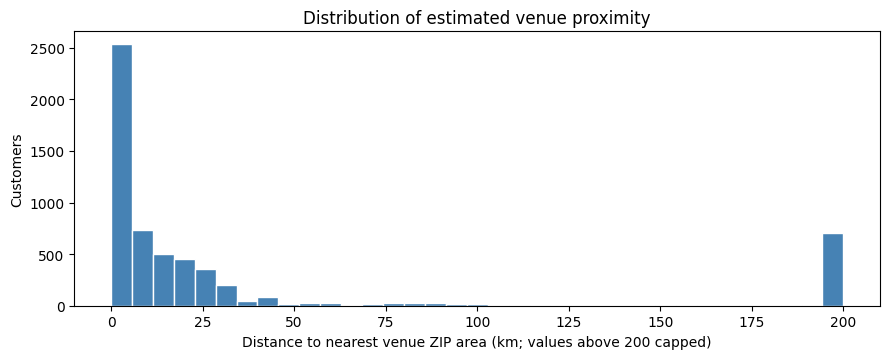

,accounts,buyers,subscription_rate
distance_quartile,,,
"(-0.001, 3.533]",1499,101,0.0674
"(3.533, 7.54]",1455,135,0.0928
"(7.54, 24.509]",1448,70,0.0483
"(24.509, 4185.447]",1467,26,0.0177


In [3]:
dist_col = 'geo_distance_nearest_km'
if dist_col in train:
    fig, ax = plt.subplots(figsize=(9, 3.7))
    nearest = train[dist_col].dropna()
    ax.hist(nearest.clip(upper=200), bins=35, color='steelblue', edgecolor='white')
    ax.set(xlabel='Distance to nearest venue ZIP area (km; values above 200 capped)',
           ylabel='Customers', title='Distribution of estimated venue proximity')
    plt.tight_layout()
    plt.show()

    valid = train[train[dist_col].notna()].copy()
    valid['distance_quartile'] = pd.qcut(valid[dist_col], q=4, duplicates='drop')
    table = valid.groupby('distance_quartile', observed=True)['label'].agg(
        accounts='size', buyers='sum', subscription_rate='mean'
    )
    display(table.round(4))
else:
    print('Distance features were not included in this experiment selection.')

## 4. Compare out-of-fold model performance
`delta_auc_vs_baseline = candidate AUROC − original-feature AUROC`. Positive values mean improvements; negative values mean worse performance. With one seed, the AUROC standard deviation across seeds appears as 0.0 by construction and is **not** a stability estimate.

,mode,n_features,mean_oof_auc,std_oof_auc,mean_oof_average_precision,delta_auc_vs_baseline
0,distance,46,0.97255,0.0,0.82996,0.00116
1,demographics,44,0.97160,0.0,0.82932,0.00021
2,baseline,39,0.97139,0.0,0.84040,0.00000
3,density,43,0.97112,0.0,0.83011,-0.00027
4,all,55,0.97077,0.0,0.82172,-0.00062


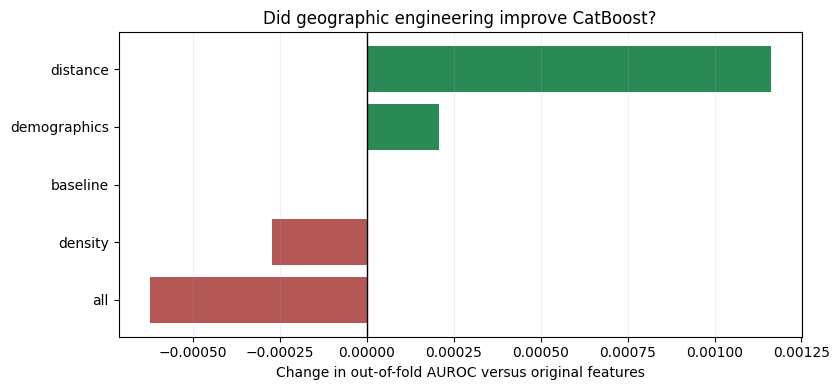

Baseline at seed 42: 0.97139 (expected about 0.97139)


In [4]:
display(summary[['mode', 'n_features', 'mean_oof_auc', 'std_oof_auc',
                 'mean_oof_average_precision', 'delta_auc_vs_baseline']].round(5))

ordered = summary.sort_values('delta_auc_vs_baseline')
fig, ax = plt.subplots(figsize=(8.5, 4))
colors = ['#2a8a56' if v > 0 else '#b35854' if v < 0 else 'gray'
          for v in ordered['delta_auc_vs_baseline']]
ax.barh(ordered['mode'], ordered['delta_auc_vs_baseline'], color=colors)
ax.axvline(0, color='black', lw=1)
ax.set(xlabel='Change in out-of-fold AUROC versus original features',
       title='Did geographic engineering improve CatBoost?')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

if 42 in config['seeds'] and config['folds'] == 5:
    baseline = runs.loc[(runs['seed'] == 42) & (runs['mode'] == 'baseline'), 'oof_auc'].iloc[0]
    print(f'Baseline at seed 42: {baseline:.5f} (expected about 0.97139)')

## 5. Does the improvement hold across seeds?
All variants at a given seed share the same account-level folds and fixed CatBoost settings. The paired score differences help separate feature gains from variation caused by changing the CV partition.

In [5]:
per_seed = runs.pivot(index='mode', columns='seed', values='delta_auc_vs_baseline')
display(per_seed.round(5))
if len(config['seeds']) > 1:
    fig, ax = plt.subplots(figsize=(8.5, 4.3))
    for seed in per_seed.columns:
        ax.scatter(per_seed.index, per_seed[seed], label=f'Seed {seed}', s=65)
    ax.axhline(0, linestyle='--', color='gray')
    ax.set(ylabel='AUROC gain relative to original features',
           title='Stability of geographic feature improvements')
    ax.tick_params(axis='x', labelrotation=20)
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Optional validation: python -m src.geography_experiments --seeds 42 123 2026')

seed,42
mode,
all,-0.00062
baseline,0.00000
demographics,0.00021
density,-0.00027
distance,0.00116


Optional validation: python -m src.geography_experiments --seeds 42 123 2026


## 6. Which new geographic features does CatBoost use?
CatBoost feature importance is descriptive and shared among correlated inputs. The strongest evidence of utility remains the **paired AUROC change** when feature groups are added.

In [6]:
if importance is not None:
    new_geo = importance[(importance['feature'].str.startswith('geo_')) &
                         (importance['mode'] != 'baseline')]
    ranked = (new_geo.groupby(['mode', 'feature'])['importance_mean'].mean()
              .reset_index().sort_values(['mode', 'importance_mean'], ascending=[True, False]))
    display(ranked.groupby('mode').head(8).round(3))
else:
    print('Feature-importance report is unavailable.')

,mode,feature,importance_mean
9,all,geo_zip_other_active_share_smoothed,5.356
15,all,geo_zip_wages_per_return,3.969
11,all,geo_zip_other_patron_count,3.728
12,all,geo_zip_people_per_return,3.601
8,all,geo_zip_log_other_patrons,2.670
1,all,geo_distance_nearest_km,2.588
3,all,geo_distance_peninsula_km,2.502
5,all,geo_distance_stanford_km,2.424
20,demographics,geo_zip_wages_per_return,7.483
17,demographics,geo_zip_people_per_return,5.138


## 7. How reliable is the strongest candidate's improvement?
Optional account-level paired bootstrap for the first seed. The interval reflects one cross-validation run and does not substitute for testing across multiple seeds or the private Kaggle test set.

In [7]:
best_mode = summary.iloc[0]['mode']
if best_mode == 'baseline':
    print('The original feature set currently has the highest mean AUROC.')
else:
    chosen_seed = config['seeds'][0]
    base = oof[f'pred_baseline_seed_{chosen_seed}'].to_numpy()
    other = oof[f'pred_{best_mode}_seed_{chosen_seed}'].to_numpy()
    labels = oof['label'].to_numpy()
    rng = np.random.default_rng(2026)
    changes = []
    for _ in range(400):
        ix = rng.integers(0, len(labels), len(labels))
        if len(np.unique(labels[ix])) < 2:
            continue
        changes.append(roc_auc_score(labels[ix], other[ix]) -
                       roc_auc_score(labels[ix], base[ix]))
    print(f'{best_mode} vs baseline (seed {chosen_seed})')
    print('Paired 95% interval for AUROC gain:',
          np.round(np.quantile(changes, [0.025, 0.5, 0.975]), 5))

distance vs baseline (seed 42)
Paired 95% interval for AUROC gain: [-0.00182  0.00091  0.00437]


## 8. Conclusions and next experiments

Fill this in after evaluating the results:

- **Reproducibility:** Did the baseline match the expected AUROC at seed 42?
- **Most valuable geographic group:** Demographics, distance, local historical audience density, or their combination?
- **Magnitude and stability:** How large is the paired AUROC gain? Does it hold across seeds?
- **Data quality:** Do any new columns have problematic missingness or extreme values?
- **Next milestone:** Retain only feature additions supported by validation; then test CatBoost tuning and/or model ensembling without using the Kaggle leaderboard as a tuning signal.